# Lindblad: $T_1$, $T_2$ e la morte delle oscillazioni di Rabi

### Subject: Quantum electronics

`01_rabi_oscillations` integra Schrödinger: il qubit oscilla per sempre.
Un atomo vero decade. L'equazione di Lindblad aggiunge i jump

$$
\dot\rho=-i[H,\rho]+\sum_k\Bigl(L_k\rho L_k^\dagger
-\tfrac12\{L_k^\dagger L_k,\rho\}\Bigr),
$$

con $L_1=\sqrt{\gamma}\,\sigma_-$ (rilassamento, $T_1=1/\gamma$) e
$L_\varphi=\sqrt{\gamma_\varphi/2}\,\sigma_z$ (dephasing puro).
Vale

$$
\frac1{T_2}=\frac1{2T_1}+\gamma_\varphi.
$$

Stesso Hamiltoniano risonante $H=\Omega\sigma_x/2$ del notebook 01;
qui $\rho$ non resta pura.


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

def rk4(f, y0, t):
    y = np.empty((len(t),) + np.shape(y0), dtype=np.asarray(y0).dtype)
    y[0] = y0
    for i in range(len(t) - 1):
        h = t[i + 1] - t[i]
        k1 = f(t[i], y[i])
        k2 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k1)
        k3 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k2)
        k4 = f(t[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

print("Setup ready.")


Setup ready.


## 1. Propagatore Lindblad (RK4 su $\rho$)


In [2]:
sx = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
sy = np.array([[0.0, -1j], [1j, 0.0]], dtype=complex)
sz = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
sm = np.array([[0.0, 1.0], [0.0, 0.0]], dtype=complex)  # |g><e|
sp = sm.conj().T
I2 = np.eye(2, dtype=complex)


def bloch(rho):
    return np.array(
        [
            np.real(np.trace(rho @ sx)),
            np.real(np.trace(rho @ sy)),
            np.real(np.trace(rho @ sz)),
        ]
    )


def lindblad_f(H, Ls):
    def f(t, y):
        rho = y.reshape(2, 2)
        dr = -1j * (H @ rho - rho @ H)
        for L in Ls:
            LdL = L.conj().T @ L
            dr = dr + L @ rho @ L.conj().T - 0.5 * (LdL @ rho + rho @ LdL)
        return dr.reshape(4)

    return f


def evolve(H, Ls, rho0, t):
    y = rk4(lindblad_f(H, Ls), rho0.reshape(4), t)
    rhos = y.reshape(-1, 2, 2)
    # numerical drift off hermiticity / trace: report, do not "fix"
    return rhos


Omega = 2.0 * np.pi  # one Rabi cycle per unit time
H = 0.5 * Omega * sx
rho0 = np.array([[1.0, 0.0], [0.0, 0.0]], dtype=complex)  # |0>
t = np.linspace(0.0, 4.0, 1601)
print("operators ready.")


operators ready.


## 2. Check: $\gamma=0$ riproduce Rabi unitario

Popolazione eccitata $P_e=(1-\langle Z\rangle)/2=\sin^2(\Omega t/2)$.
Purezza $\mathrm{Tr}(\rho^2)=1$.


Rabi vs sin²: max |ΔPe| = 5.99e-09
min purity (unitary) = 1.000000


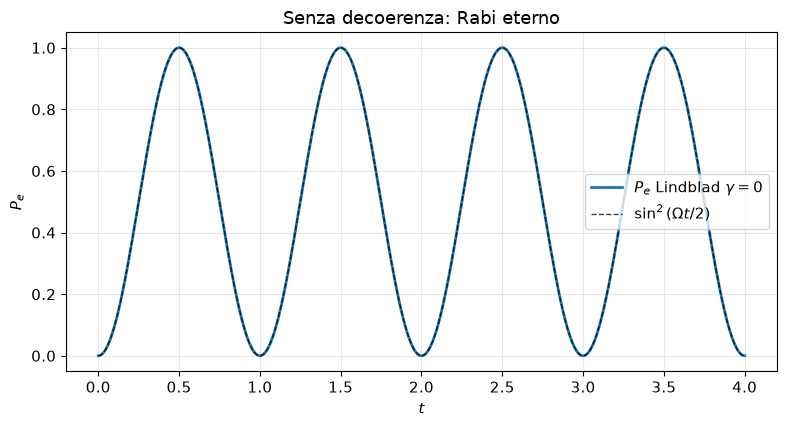

In [3]:
rhos_u = evolve(H, [], rho0, t)
Pe_u = np.real(rhos_u[:, 1, 1])
purity_u = np.array([np.real(np.trace(r @ r)) for r in rhos_u])
Pe_th = np.sin(Omega * t / 2.0) ** 2
err = np.max(np.abs(Pe_u - Pe_th))
print(f"Rabi vs sin²: max |ΔPe| = {err:.2e}")
print(f"min purity (unitary) = {purity_u.min():.6f}")
assert err < 3e-4
assert purity_u.min() > 0.999

fig, ax = plt.subplots()
ax.plot(t, Pe_u, lw=2, label=r"$P_e$ Lindblad $\gamma=0$")
ax.plot(t, Pe_th, "k--", lw=1.0, alpha=0.75, label=r"$\sin^2(\Omega t/2)$")
ax.set_xlabel("$t$")
ax.set_ylabel(r"$P_e$")
ax.legend()
ax.set_title("Senza decoerenza: Rabi eterno")
plt.tight_layout()
plt.show()


## 3. $T_1$ da solo: l'inviluppo muore, $\rho\to\lvert 0\rangle$

$\gamma=1/T_1$, $\gamma_\varphi=0$. Le coerenze decadono come
$e^{-t/(2T_1)}$; a tempi lunghi $P_e\to 0$, non a $1/2$.


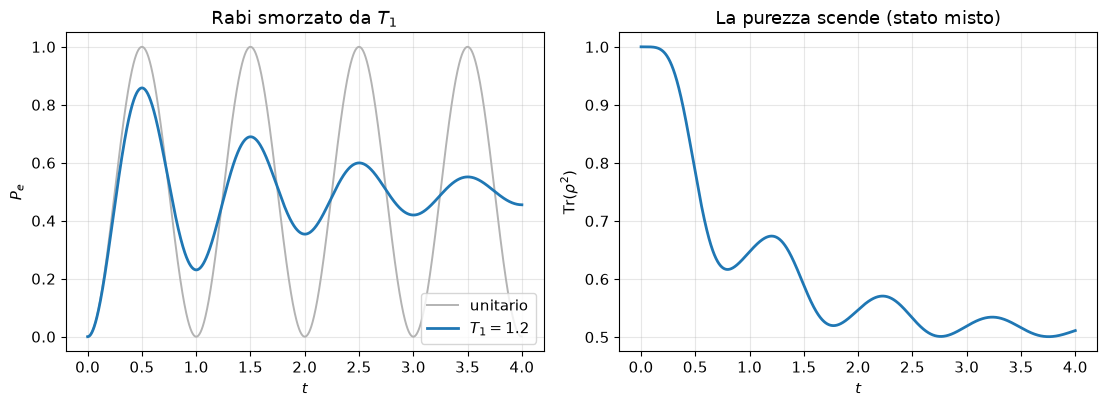

Pe(t=end) = 0.4550  (deve tendere a 0)
purity min = 0.501


In [4]:
T1 = 1.2
gamma = 1.0 / T1
L1 = np.sqrt(gamma) * sm
rhos_t1 = evolve(H, [L1], rho0, t)
Pe_t1 = np.real(rhos_t1[:, 1, 1])
purity_t1 = np.array([np.real(np.trace(r @ r)) for r in rhos_t1])
bloch_t1 = np.stack([bloch(r) for r in rhos_t1], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
axes[0].plot(t, Pe_u, color="0.7", lw=1.4, label="unitario")
axes[0].plot(t, Pe_t1, lw=2, label=rf"$T_1={T1}$")
axes[0].set_xlabel("$t$")
axes[0].set_ylabel(r"$P_e$")
axes[0].legend()
axes[0].set_title("Rabi smorzato da $T_1$")
axes[1].plot(t, purity_t1, lw=2)
axes[1].set_xlabel("$t$")
axes[1].set_ylabel(r"$\mathrm{Tr}(\rho^2)$")
axes[1].set_title("La purezza scende (stato misto)")
plt.tight_layout()
plt.show()
print(f"Pe(t=end) = {Pe_t1[-1]:.4f}  (deve tendere a 0)")
print(f"purity min = {purity_t1.min():.3f}")


## 4. Dephasing extra: $T_2<2T_1$

Stesso $T_1$, più $\gamma_\varphi$ tale che $T_2=0.6$. Le oscillazioni
muoiono prima; asintoto di popolazione ancora $\lvert 0\rangle$.
Sulla sfera di Bloch il raggio si contrae più in $xy$ che in $z$.


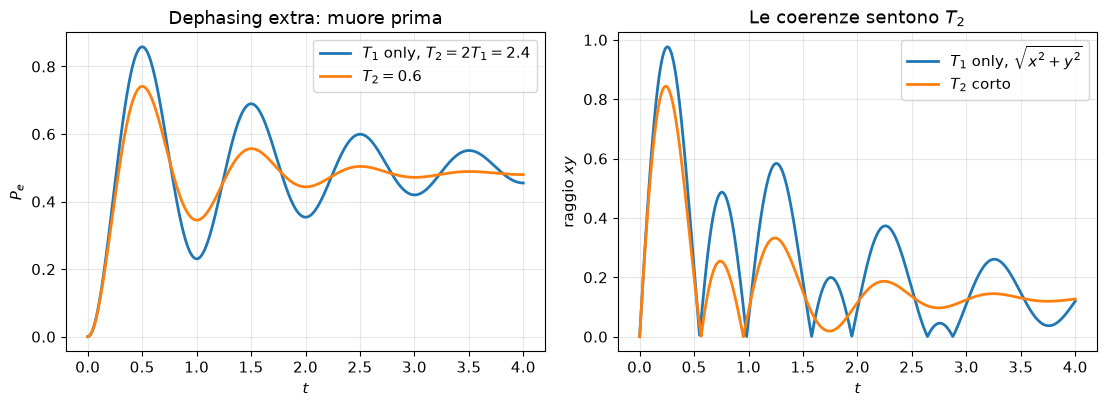

γ_φ = 1.250  (1/T2 − 1/(2T1))


In [5]:
T2 = 0.6
gamma_phi = 1.0 / T2 - 0.5 / T1
assert gamma_phi > 0
Lphi = np.sqrt(gamma_phi / 2.0) * sz
rhos_t2 = evolve(H, [L1, Lphi], rho0, t)
Pe_t2 = np.real(rhos_t2[:, 1, 1])
xy_t1 = np.sqrt(bloch_t1[:, 0] ** 2 + bloch_t1[:, 1] ** 2)
bloch_t2 = np.stack([bloch(r) for r in rhos_t2], axis=0)
xy_t2 = np.sqrt(bloch_t2[:, 0] ** 2 + bloch_t2[:, 1] ** 2)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
axes[0].plot(t, Pe_t1, lw=2, label=rf"$T_1$ only, $T_2=2T_1={2*T1:.1f}$")
axes[0].plot(t, Pe_t2, lw=2, label=rf"$T_2={T2}$")
axes[0].set_xlabel("$t$")
axes[0].set_ylabel(r"$P_e$")
axes[0].legend()
axes[0].set_title("Dephasing extra: muore prima")
axes[1].plot(t, xy_t1, lw=2, label=r"$T_1$ only, $\sqrt{x^2+y^2}$")
axes[1].plot(t, xy_t2, lw=2, label=r"$T_2$ corto")
axes[1].set_xlabel("$t$")
axes[1].set_ylabel("raggio $xy$")
axes[1].legend()
axes[1].set_title("Le coerenze sentono $T_2$")
plt.tight_layout()
plt.show()
print(f"γ_φ = {gamma_phi:.3f}  (1/T2 − 1/(2T1))")


## Takeaway

Un gate $\pi$ ha senso solo se $\Omega T_2\gg 1$. Lindblad è il ponte
tra il laser a due livelli (Sibilia) e il qubit rumoroso (Bovino /
computing). Schrödinger da solo mente: predice un computer quantistico
eterno.

## Next step
- Impulso $\pi$ e $\pi/2$ con $T_2$ finito: fidelity vs durata.
- Spettro di assorbimento: Fourier della coerenza = Lorentziana di
  larghezza $1/T_2$.
